In [7]:
#Reading the csv file 
import pandas as pd 
from pandas import read_csv
#plotting the graph
from matplotlib import pyplot 
#train test split
from sklearn.model_selection import train_test_split
#validation curve
from sklearn.model_selection import cross_val_score
#importing the KFold class
from sklearn.model_selection import StratifiedKFold
#Importing the Logistic Regression model
from sklearn.linear_model import LogisticRegression
#Importing the KNN classifier
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
url="https://github.com/jbrownlee/Datasets/raw/master/iris.csv"
names = ['sepal-length', 'sepal-width', 'petal-length', 'petal-width', 'class']
dataset = read_csv(url, names=names)
print(dataset)
#Split the dataset into Training,Testing and Validation sets
array = dataset.values
X = array[:,0:4]
Y = array[:,4]
#we are creating a trainning and validation set using train test split
#test size=0.20 means 20% of the data will be used for validation and 80% for training
#random_state=1 means that the data will be shuffled before splitting and the same random state will be used for reproducibility
#shuffle=True means that the data will be shuffled before splitting
x_train,x_validation,y_train,y_validation = train_test_split(X,Y,test_size=0.20,random_state=1,shuffle=True)

     sepal-length  sepal-width  petal-length  petal-width           class
0             5.1          3.5           1.4          0.2     Iris-setosa
1             4.9          3.0           1.4          0.2     Iris-setosa
2             4.7          3.2           1.3          0.2     Iris-setosa
3             4.6          3.1           1.5          0.2     Iris-setosa
4             5.0          3.6           1.4          0.2     Iris-setosa
..            ...          ...           ...          ...             ...
145           6.7          3.0           5.2          2.3  Iris-virginica
146           6.3          2.5           5.0          1.9  Iris-virginica
147           6.5          3.0           5.2          2.0  Iris-virginica
148           6.2          3.4           5.4          2.3  Iris-virginica
149           5.9          3.0           5.1          1.8  Iris-virginica

[150 rows x 5 columns]


[('LR', LogisticRegression(max_iter=1000)), ('KNN', KNeighborsClassifier())]
LR: 0.966667 (0.040825)
KNN: 0.958333 (0.041667)


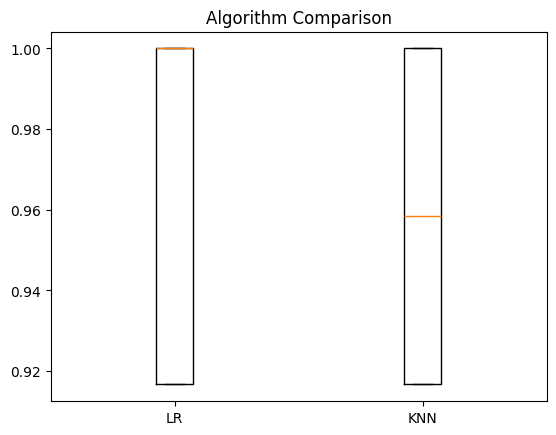

In [19]:
#empty list to store the mean accuracy of each model
models = []
#liblinear means 0 and 1
models.append(('LR', LogisticRegression(solver='lbfgs', max_iter=1000)))
models.append(('KNN', KNeighborsClassifier()))
print(models)
results = []
names = []
for name, model in models:
      #kfold cross validation with 10 folds
      kfold = StratifiedKFold(n_splits=10, random_state=1, shuffle=True)
      cv_results = cross_val_score(model, x_train, y_train, cv=kfold, scoring='accuracy')
      results.append(cv_results)
      names.append(name)
      print('%s: %f (%f)' % (name, cv_results.mean(), cv_results.std()))
#Compare the algorithms
pyplot.boxplot(results, tick_labels=names)
pyplot.title('Algorithm Comparison')
pyplot.show()

In [25]:
X=[10,20,30,40,50,60]
Y=[30,12,34,32,65,50]
#Find for 34 and 20
#Given k=2
#Using KNN
for i in X:
    print(i)
for j in Y:
      print(j)

10
20
30
40
50
60
30
12
34
32
65
50


In [ ]:
import math 
x1=34
x2=20
k=2
distances = []
for i in range(len(X)):
    distance = math.sqrt((X[i]-x1)**2 + (Y[i]-x2)**2)
    distances.append(distance)
print(distances)


[26.0, 16.1245154965971, 14.560219778561036, 13.416407864998739, 47.75981574503821, 39.698866482558415]


In [28]:
from sklearn.cluster import KMeans

X = [10, 20, 30, 40, 50, 60]
Y = [30, 12, 34, 32, 65, 50]

data = list(zip(X, Y))

kmeans = KMeans(n_clusters=2, random_state=1, n_init=10)

kmeans.fit(data)

print("Cluster labels:", kmeans.labels_)
print("Centroids:", kmeans.cluster_centers_)

Cluster labels: [0 0 0 0 1 1]
Centroids: [[25.  27. ]
 [55.  57.5]]
